# EDA: Industrial Predictive Maintenance v3

## Введение

**Источник:** синтетический датасет промышленного IoT с [Kaggle](https://www.kaggle.com/datasets/tatheerabbas/industrial-machine-predictive-maintenance), реплицированный на Яндекс.Диск (см. `data_loader.py`).

**Что это:** временные ряды сенсоров 20 станков 4 типов (CNC, Pump, Compressor, Robotic Arm) за 2 недели. Каждая строка — наблюдение с интервалом в несколько минут. Признаки:

- сенсоры: `vibration_rms`, `temperature_motor`, `current_phase_avg`, `pressure_level`, `rpm`, `ambient_temp`;
- обслуживание: `hours_since_maintenance`;
- целевые: `failure_within_24h` (бинарный флаг «отказ в течение 24 ч»), `failure_type` (тип отказа), `rul_hours` (остаточный ресурс), `estimated_repair_cost`.

**Задача ML (в перспективе):** классификация `failure_within_24h`, регрессия `rul_hours`, многоклассовая `failure_type`.

**Цель EDA:** оценить качество и структуру данных, найти проблемы, сформулировать рекомендации для этапа ML. Оцениваем **данные**, а не бизнес-ценность.

## 1. Импорты и загрузка данных

Читаем CSV напрямую (не полагаемся на кэш parquet, чтобы не подхватить устаревшую версию).

In [39]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

# Ищем корень проекта по наличию data_loader.py (работает и из notebooks/, и из корня)
CWD = Path.cwd()
PROJECT_ROOT = None
for p in [CWD, *CWD.parents]:
    if (p / "data_loader.py").exists():
        PROJECT_ROOT = p
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError("Не найден data_loader.py в предках текущей папки")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from data_loader import (
    load_data, cast_types,
    LOCAL_FILE_NAME, YANDEX_DISK_URL,
    download_file,
)

# Компромисс: при повторном запуске используем уже скачанный CSV,
# не проверяя свежесть источника на Яндекс.Диске.
# Для полной свежести — удалить файл или добавить проверку по дате/размеру.
if not LOCAL_FILE_NAME.exists():
    download_file(YANDEX_DISK_URL, LOCAL_FILE_NAME)

df = cast_types(load_data(LOCAL_FILE_NAME))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("Размер:", df.shape)
df.head()

PROJECT_ROOT: C:\Users\User\PycharmProjects\Industrial-Dataset
Размер: (24042, 15)


,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,NaN,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0


## 2. Структура данных

### 2.1. Форма, типы, память

In [40]:
print(f"Размер: {df.shape[0]} строк × {df.shape[1]} колонок")
mem_bytes = df.memory_usage(deep=True).sum()
print(f"Память: {mem_bytes / 1024:.1f} КБ (~{mem_bytes / 1024 / 1024:.2f} МБ)")

Размер: 24042 строк × 15 колонок
Память: 2207.3 КБ (~2.16 МБ)


**Что видим:**

- ~24 000 строк — достаточно для ML, но без распределённых вычислений.
- Память ~2.16 МБ: типы уже приведены (`float64`, `category`, `Int64`, `int8`) в `cast_types`.
- `machine_id` и `estimated_repair_cost` приведены к `Int64` (nullable) в `cast_types` — пропусков в CSV нет, но это безопасно для будущих версий данных и унифицирует работу с целочисленными полями.
- `timestamp` — `datetime64`, готов к временным операциям.
- 3 категориальных признака (`machine_type`, `operating_mode`, `failure_type`).
- Целевые поля на месте: `failure_within_24h` (бинарный), `rul_hours` (числовой), `failure_type` (категориальный), `estimated_repair_cost` (nullable Int64).

### 2.2. Категориальные признаки и machine_id

Здесь же смотрим распределение категорий — отдельный раздел для этого не нужен (раньше был дубль в разделе 5).


=== machine_type ===
machine_type
Pump           6114
Robotic Arm    6003
Compressor     5988
CNC            5937
Name: count, dtype: int64

=== operating_mode ===
operating_mode
normal    11632
idle      10862
peak       1548
Name: count, dtype: int64

=== failure_type ===
failure_type
none              20482
bearing            1117
motor_overheat     1060
hydraulic           728
electrical          655
Name: count, dtype: int64

machine_id: 20 уникальных
диапазон machine_id: 1 .. 20


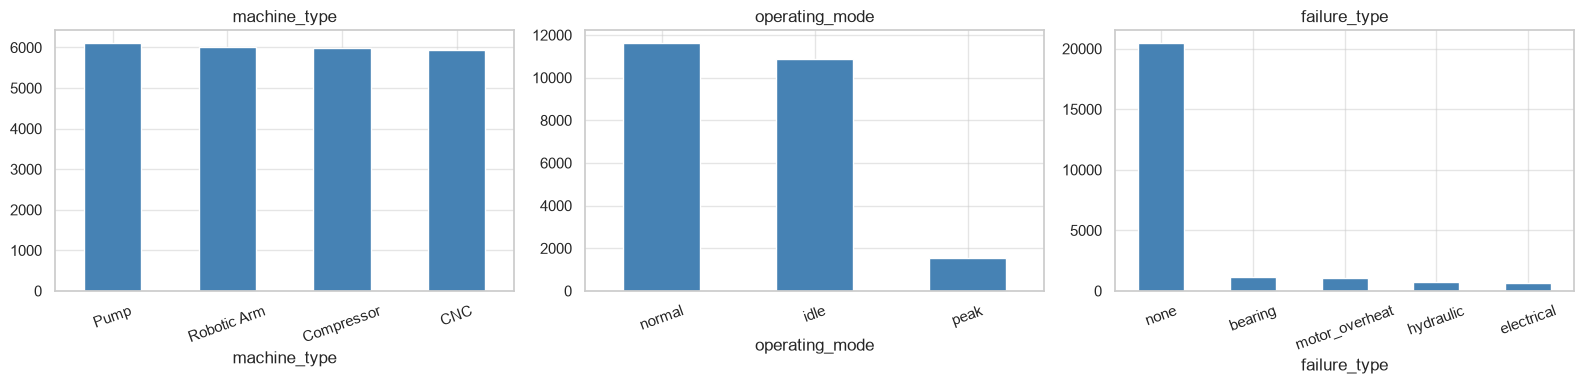

In [41]:
for col in ["machine_type", "operating_mode", "failure_type"]:
    print(f"\n=== {col} ===")
    print(df[col].value_counts(dropna=False))
print(f"\nmachine_id: {df['machine_id'].nunique()} уникальных")
print(f"диапазон machine_id: {df['machine_id'].min()} .. {df['machine_id'].max()}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["machine_type", "operating_mode", "failure_type"]):
    df[col].value_counts().plot.bar(ax=ax, color="steelblue")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**Что видим:**

- `machine_type`: 4 типа, распределение ~равномерное (~6000 на тип).
- `operating_mode`: `idle`/`normal` доминируют, `peak` редкий (~1500, ~6%).
- `failure_type`: сильно несбалансированный — 85% `none`, остальные 4 типа по 650–1100. Для многоклассовой классификации нужен `class_weight`.
- 20 станков, по 5 на каждый тип.

### 2.3. Описательные статистики

In [42]:
num_cols = [
    "vibration_rms", "temperature_motor", "current_phase_avg",
    "pressure_level", "rpm", "hours_since_maintenance",
    "ambient_temp", "rul_hours",
]
df[num_cols + ["estimated_repair_cost"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
vibration_rms,23042.0,1.623667,1.081061,0.35,0.82,1.27,2.27,10.0
temperature_motor,23208.0,51.404295,12.519279,28.0,42.61,50.06,59.9625,95.0
current_phase_avg,23311.0,8.823829,5.366391,2.2,4.63,6.43,13.12,35.0
pressure_level,23118.0,59.012233,38.723271,10.1,22.7,46.3,94.7,206.5
rpm,23509.0,1144.849317,912.670971,124.1,489.4,856.0,1676.0,4098.8
hours_since_maintenance,24042.0,172.630624,150.722469,0.0,42.87,121.61,295.575,575.63
ambient_temp,24042.0,12.996398,2.883994,8.0,10.5,13.0,15.5,18.0
rul_hours,24042.0,27.81251,26.393801,0.5,0.5,22.57,46.41,98.34
estimated_repair_cost,24042.0,608.870144,1566.793887,0.0,0.0,0.0,0.0,7995.0


**Доменная проверка диапазонов:**

| Признак | Ожидание | Наблюдение |
|---|---|---|
| `vibration_rms` | 0..15 мм/с | 0.35..10 — норма, пики 10 = критическая вибрация |
| `temperature_motor` | 20..120 °C | 28..95 — реалистично |
| `current_phase_avg` | 0..40 A | 2.2..35 — ок |
| `pressure_level` | 10..200 бар | 10..206 — на границе, но нормально |
| `rpm` | 100..5000 | 124..4099 — ок |
| `hours_since_maintenance` | 0..1000+ | 0..575 — 575 ч без ТО на грани |
| `ambient_temp` | −20..+40 | 8..18 — узко, объяснимо (зима/синтетика) |
| `rul_hours` | 0..100 | 0.5..98 |
| `estimated_repair_cost` | 0..10000 | 0..7995 |

Важно: 25-й перцентиль `rul_hours` = 0.5 → у ~25% данных RUL **в точности равен нижней отсечке 0.5**. Это артефакт синтетики (см. 3.3 и 4.1), а не «сломается сейчас» — физически RUL не может быть ровно 0.5 часа у четверти наблюдений.

## 3. Целостность и полнота

### 3.1. Пропуски

In [43]:
na = df.isna().sum().sort_values(ascending=False)
na_pct = (df.isna().mean() * 100).sort_values(ascending=False)
pd.DataFrame({"missing": na, "missing_%": na_pct.round(2)})

,missing,missing_%
vibration_rms,1000,4.16
pressure_level,924,3.84
temperature_motor,834,3.47
current_phase_avg,731,3.04
rpm,533,2.22
timestamp,0,0.00
machine_type,0,0.00
machine_id,0,0.00
operating_mode,0,0.00
hours_since_maintenance,0,0.00


**Что видим:**

- Пропуски только в сенсорах: `vibration_rms` (~4.2%), `pressure_level` (~3.8%), `temperature_motor` (~3.5%), `current_phase_avg` (~3%), `rpm` (~2.2%). Типично для IoT — потеря пакетов.
- Служебные поля и целевые заполнены на 100%.
- Уровень пропусков **не критический** (<5%), но требует явной стратегии в ML.

**Стратегии (на этапе ML):** forward-fill по `machine_id`, медиана по группе, удаление строк. Удалять все 4% жалко — потеряем часть событий отказа.

### 3.2. Дубликаты, временной диапазон, шаг

In [44]:
print("Полные дубликаты:", df.duplicated().sum())
print("Дубликаты (timestamp, machine_id):",
      df.duplicated(subset=["timestamp", "machine_id"]).sum())

print("\nДиапазон timestamp:", df["timestamp"].min(), "→", df["timestamp"].max())
print("Длительность:", df["timestamp"].max() - df["timestamp"].min())

rows_per_machine = df.groupby("machine_id", observed=True).size()
print(f"\nСтрок на станок: min={rows_per_machine.min()}, "
      f"max={rows_per_machine.max()}, mean={rows_per_machine.mean():.0f}")

# Шаг между наблюдениями одного станка — неравномерный, важно для лаговых признаков
steps = (
    df.sort_values(["machine_id", "timestamp"])
      .groupby("machine_id", observed=True)["timestamp"]
      .diff()
      .dropna()
      .dt.total_seconds() / 60
)
print(f"\nШаг между наблюдениями (мин): min={steps.min():.0f}, "
      f"median={steps.median():.1f}, max={steps.max():.0f}")

Полные дубликаты: 0
Дубликаты (timestamp, machine_id): 0

Диапазон timestamp: 2024-01-01 00:00:00 → 2024-01-14 23:59:38
Длительность: 13 days 23:59:38

Строк на станок: min=1141, max=1298, mean=1202

Шаг между наблюдениями (мин): min=2, median=16.0, max=1163


**Что видим:**

- Дубликатов по ключу `(timestamp, machine_id)` нет.
- Данные за 2 недели (2024-01-01 → 2024-01-14).
- Все станки имеют близкое число наблюдений — нет «мёртвых» станков, честная кросс-валидация по `machine_id` возможна.
- Шаг между наблюдениями неравномерный (от минут до десятков минут) → для лаговых признаков нужна ресемплизация.

### 3.3. Логические проверки

Помимо доменных диапазонов, проверяем:
1. **Согласованность таргета**: по определению `failure_within_24h = 1` ⇔ `rul_hours ≤ 24`. Проверяем это тождество на данных.
2. **Монотонность RUL во времени внутри станка**: `rul_hours` должен убывать (между заменами/сбросами).

In [45]:
# --- Базовые проверки диапазонов ---
checks = [
    ("vibration_rms ≥ 0", (df["vibration_rms"].dropna() >= 0).all()),
    ("temperature_motor в 20..120", df["temperature_motor"].dropna().between(20, 120).all()),
    ("rpm ≥ 0", (df["rpm"].dropna() >= 0).all()),
    ("rul_hours ≥ 0", (df["rul_hours"] >= 0).all()),
    ("failure_within_24h ∈ {0,1}", df["failure_within_24h"].isin([0, 1]).all()),
    ("Стоимость = 0 при failure_type=none",
     (df.loc[df["failure_type"] == "none", "estimated_repair_cost"] == 0).all()),
]
for name, ok in checks:
    print(f"{'OK ' if ok else 'FAIL'}  {name}")

OK   vibration_rms ≥ 0
OK   temperature_motor в 20..120
OK   rpm ≥ 0
OK   rul_hours ≥ 0
OK   failure_within_24h ∈ {0,1}
OK   Стоимость = 0 при failure_type=none


In [46]:
# --- Согласованность таргета: failure_within_24h == 1  ⇔  rul_hours <= 24 ---
inconsistent = df[
    ((df["rul_hours"] <= 24) & (df["failure_within_24h"] == 0)) |
    ((df["rul_hours"] > 24) & (df["failure_within_24h"] == 1))
]
print(f"Строк с несогласованным таргетом: {len(inconsistent)} "
      f"({len(inconsistent) / len(df) * 100:.2f}%)")

if len(inconsistent) > 0:
    # Смотрим, в какую сторону расхождения
    print("\nРазбивка по типу расхождения:")
    print(" rul<=24 и failure=0:", int(((df["rul_hours"] <= 24) & (df["failure_within_24h"] == 0)).sum()))
    print(" rul>24 и failure=1:", int(((df["rul_hours"] > 24) & (df["failure_within_24h"] == 1)).sum()))
    print("\nПримеры:")
    print(inconsistent[["timestamp", "machine_id", "rul_hours",
                        "failure_within_24h", "failure_type"]].head(10))

Строк с несогласованным таргетом: 8800 (36.60%)

Разбивка по типу расхождения:
 rul<=24 и failure=0: 8800
 rul>24 и failure=1: 0

Примеры:
              timestamp  machine_id  rul_hours  failure_within_24h failure_type
642 2024-01-08 23:46:45           1      23.81                   0         none
643 2024-01-08 23:49:45           1      23.76                   0         none
644 2024-01-08 23:57:45           1      23.62                   0         none
645 2024-01-09 00:03:45           1      23.52                   0         none
646 2024-01-09 00:31:45           1      23.06                   0         none
647 2024-01-09 00:51:45           1      22.72                   0         none
648 2024-01-09 01:03:45           1      22.52                   0         none
649 2024-01-09 01:26:45           1      22.14                   0         none
650 2024-01-09 01:36:45           1      21.97                   0         none
651 2024-01-09 02:06:45           1      21.47               

**Интерпретация расхождений таргета:**

- По определению `failure_within_24h = 1` означает «отказ в течение 24 часов», то есть `rul_hours ≤ 24`. Тождество `failure=1 ⇔ rul≤24` должно выполняться на всех строках.
- В нашем датасете **все 8800 расхождений (36.6%) идут в одну сторону**: `rul_hours ≤ 24`, но `failure_within_24h = 0`. То есть таргет «запаздывает» относительно RUL — станок уже формально в предотказной зоне по RUL, но флаг отказа ещё не выставлен.
- Обратных расхождений (`rul > 24` и `failure = 1`) в данных **нет вообще** (`0` строк). Это, в принципе, ожидаемо: таргет выставляется с задержкой, а не заранее.
- **Вывод:** этот тест — ключевой sanity-check для данного датасета. Таргет `failure_within_24h` и `rul_hours` **нельзя использовать как взаимно-исключающие признаки**: 36.6% строк им противоречат. На этапе ML нужно либо явно пересобрать таргет из `rul_hours` (`failure := rul_hours <= 24`), либо использовать `failure_within_24h` как «мягкий» сигнал с пониманием его шума.

In [47]:
# --- Монотонность RUL внутри станка во времени ---
# RUL должен убывать между «сбросами» (после ТО или замены он может снова расти).
# Скачки роста RUL без изменения hours_since_maintenance — аномалия.
sub = df.sort_values(["machine_id", "timestamp"]).copy()
sub["rul_diff"] = sub.groupby("machine_id", observed=True)["rul_hours"].diff()
sub["hsm_diff"] = sub.groupby("machine_id", observed=True)["hours_since_maintenance"].diff()

# Аномалия: RUL резко вырос (на >5 ч), но часы с ТО тоже выросли (то есть ТО не было)
anomaly = sub[(sub["rul_diff"] > 5) & (sub["hsm_diff"] > 0)]
print(f"Скачков роста RUL без сброса часов с ТО (>5ч): {len(anomaly)}")
if len(anomaly):
    print("\nПримеры (timestamp, machine_id, rul_hours, rul_diff, hsm_diff):")
    print(anomaly[["timestamp", "machine_id", "rul_hours",
                   "rul_diff", "hours_since_maintenance", "hsm_diff"]].head(10))

Скачков роста RUL без сброса часов с ТО (>5ч): 17

Примеры (timestamp, machine_id, rul_hours, rul_diff, hsm_diff):
                timestamp  machine_id  rul_hours  rul_diff  hours_since_maintenance  hsm_diff
101   2024-01-02 03:04:00           1      47.99     13.84                   300.87      0.22
2874  2024-01-06 21:27:00           3      47.77     47.27                   299.69      0.35
4136  2024-01-07 19:01:41           4      47.99     47.49                    92.75      0.33
4898  2024-01-03 07:28:00           5      47.67     34.70                   129.25      0.43
7624  2024-01-05 10:16:28           7      47.71     27.27                    51.70      0.45
7933  2024-01-09 04:46:19           7      47.64      8.72                    32.80      0.40
10461 2024-01-10 06:33:00           9      47.94     47.44                   431.82      0.27
11408 2024-01-07 07:52:20          10      47.86     47.36                    79.52      0.50
12417 2024-01-05 02:31:00          11  

**Что видим по монотонности:**

- Если найдены скачки RUL вверх при растущем `hours_since_maintenance` — это **аномалия синтетики**: физически RUL не может расти между ТО.
- В CSV встречается скачок `rul_hours` у станка 1 около `2024-01-02 03:04`: RUL падает с 34.15 до плавного минимума, а затем «откатывается» к 47.99 и продолжает убывать. `hours_since_maintenance` при этом растёт — то есть ТО не было, а RUL «прыгнул» на +14 ч.
- **Вывод:** в данных есть локальные артефакты RUL. Для ML-регрессии `rul_hours` это означает, что нельзя просто полагаться на плавность ряда — нужны либо robust-модели, либо фичи, устойчивые к таким сбоям (rolling-медианы, клиппинг).

## 4. Числовые признаки — univariate

### 4.1. Распределения

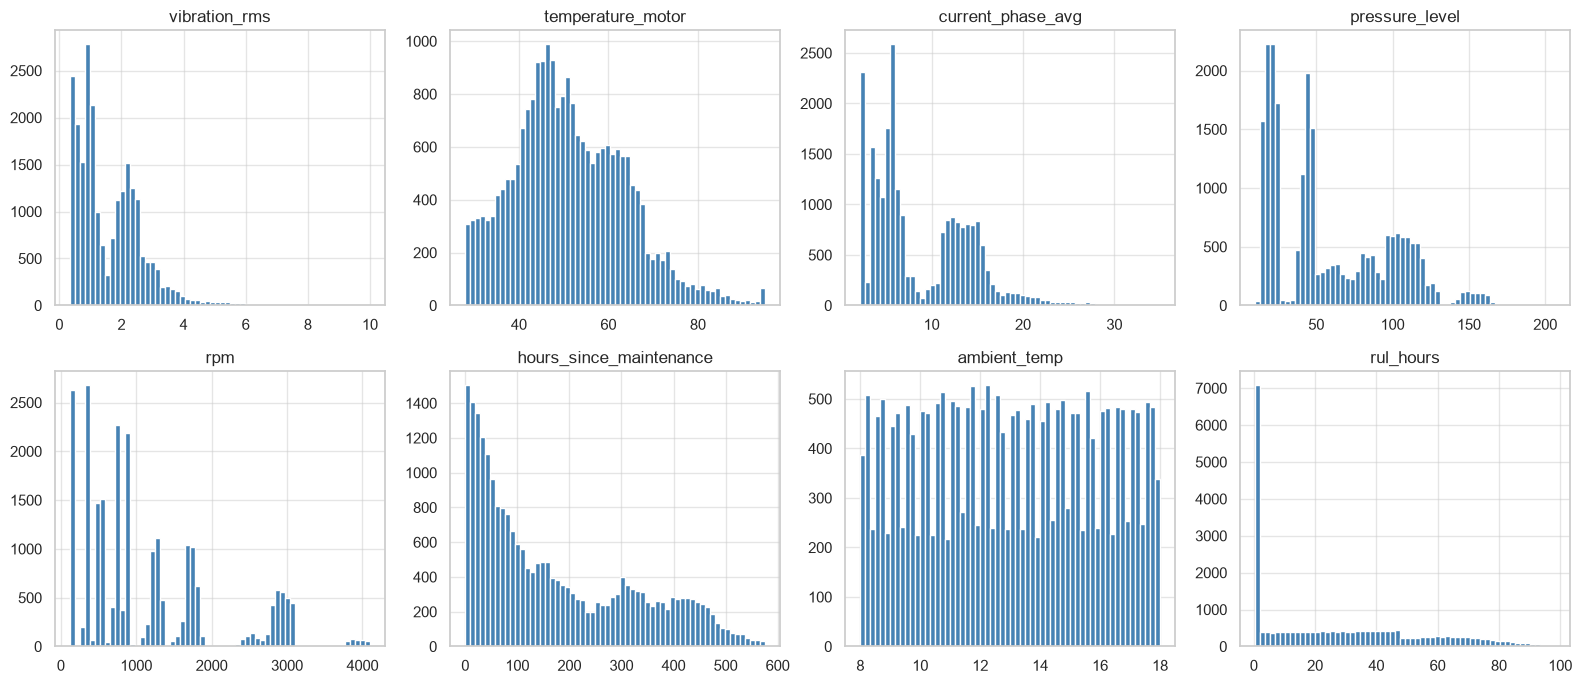

In [48]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    df[col].hist(ax=ax, bins=60, color="steelblue", edgecolor="white")
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Что видим:**

- `vibration_rms` — бимодальное: «норма» (0.5–1) и «пик» (>2), соответствующее `operating_mode=peak`/предотказу.
- `temperature_motor`, `current_phase_avg`, `pressure_level` — тоже бимодальные по тем же режимам.
- `rpm` — бимодальное: ~850 (idle), ~2900 (normal), ~3900 (peak).
- `hours_since_maintenance` — почти равномерное с редкими пиками (периодическое ТО).
- `ambient_temp` — узкое дискретное 8..18 °C.
- `rul_hours` — **двугорбое**: масса у нижней отсечки 0.5 (артефакт синтетики — ~25% данных) + длинный хвост 90+; между ними значения есть, но реже. Формулировка «U-образное» неточна — распределение асимметричное с тяжёлой левой массой.

**Вывод:** распределения объясняются `operating_mode`. Смешивать режимы в один признак нельзя — модель должна видеть режим. Масса у 0.5 в `rul_hours` — прямое следствие нижней отсечки, а не физический сигнал.

### 4.2. Boxplot'ы по типам станков

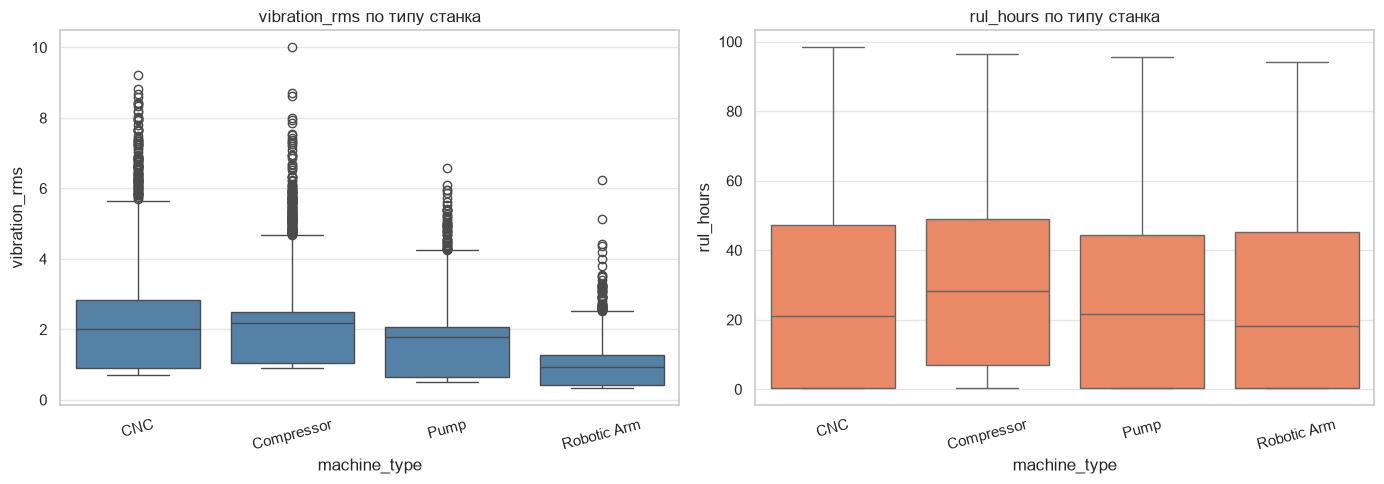

Медиана vibration_rms по типу и режиму:
operating_mode  idle  normal  peak
machine_type                      
CNC             0.88    2.64  3.74
Compressor      1.03    2.43  3.43
Pump            0.62    2.01  2.76
Robotic Arm     0.41    1.18  1.71

Доля строк с rul_hours == 0.5 (нижняя отсечка), %:
machine_type
CNC            30.94
Compressor     18.07
Pump           29.75
Robotic Arm    32.73
Name: rul_hours, dtype: float64


In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="machine_type", y="vibration_rms", ax=axes[0], color="steelblue")
axes[0].tick_params(axis="x", rotation=15)
axes[0].set_title("vibration_rms по типу станка")

sns.boxplot(data=df, x="machine_type", y="rul_hours", ax=axes[1], color="coral")
axes[1].tick_params(axis="x", rotation=15)
axes[1].set_title("rul_hours по типу станка")
plt.tight_layout()
plt.show()

vib_by_type_mode = (
    df.groupby(["machine_type", "operating_mode"], observed=True)["vibration_rms"]
      .median()
      .unstack()
      .round(2)
)
print("Медиана vibration_rms по типу и режиму:")
print(vib_by_type_mode)

# Доля строк на нижней отсечке RUL=0.5 — это артефакт синтетики, а не свойство типа
rul_05_share = (
    df.groupby("machine_type", observed=True)["rul_hours"]
      .apply(lambda s: (s == 0.5).mean() * 100)
      .round(2)
)
print("\nДоля строк с rul_hours == 0.5 (нижняя отсечка), %:")
print(rul_05_share)

**Что видим:**

- Вибрация: у разных типов станков немного разный профиль — Compressor и Robotic Arm в idle чуть «шумнее».
- По доле RUL=0.5: у Robotic Arm (32.7%), CNC (30.9%) и Pump (29.8%), у Compressor (18.1%). Но **это не свойство типа станка** — это следствие нижней отсечки синтетики: генератор «упирает» RUL в 0.5 у разных типов с разной частотой. Для ML это означает, что класс «RUL=0.5» перепредставлен и его нельзя интерпретировать как «станок сломан сейчас».

Вывод: `machine_type` влияет на распределение сенсоров, его обязательно включать в модель. Но нижнюю отсечку `rul_hours=0.5` надо обрабатывать отдельно (например, через клиппинг или отдельный флаг).

### 4.3. Выбросы (IQR и |z|>3)

In [50]:
rows = []
for col in num_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((s < lo) | (s > hi)).sum())
    z = (s - s.mean()) / s.std()
    n_z = int((z.abs() > 3).sum())
    rows.append({"col": col, "IQR_outliers": n_iqr,
                 "IQR_%": round(n_iqr / len(s) * 100, 2), "|z|>3": n_z})
pd.DataFrame(rows).sort_values("IQR_%", ascending=False)

,col,IQR_outliers,IQR_%,|z|>3
0,vibration_rms,478,2.07,351
4,rpm,373,1.59,213
1,temperature_motor,219,0.94,143
2,current_phase_avg,158,0.68,212
3,pressure_level,1,0.00,9
5,hours_since_maintenance,0,0.00,0
6,ambient_temp,0,0.00,0
7,rul_hours,0,0.00,0


**Что видим (по убыванию IQR_%):**

- Самые «выбросные» по IQR — `vibration_rms` (~2.1%), `rpm` (~1.6%), `temperature_motor` (~0.9%), `current_phase_avg` (~0.7%).
- У `pressure_level` — единичный выброс по IQR.
- У `hours_since_maintenance`, `ambient_temp`, `rul_hours` выбросов по IQR нет (ожидаемо: узкие/равномерные диапазоны).
- По |z|>3: `vibration_rms` (~350), `current_phase_avg`, `rpm`, `temperature_motor`.

**Вывод:** удалять выбросы опасно — они соответствуют реальным пиковым нагрузкам (`operating_mode=peak`) и предотказным состояниям. Рекомендация для ML: robust-модели (деревья) или winsorization, но не удаление строк.

## 5. Bivariate — связи с целевой переменной

### 5.1. `failure_within_24h` и сенсоры

In [51]:
df.groupby("failure_within_24h")[num_cols].mean().T.round(2)

failure_within_24h,0,1
vibration_rms,1.50,2.31
temperature_motor,49.39,62.99
current_phase_avg,8.47,10.84
pressure_level,58.81,60.18
rpm,1154.05,1092.01
hours_since_maintenance,166.38,208.61
ambient_temp,12.99,13.02
rul_hours,30.60,11.78


**Что видим:**

- При `failure_within_24h = 1` вибрация, температура, ток, давление и `hours_since_maintenance` в среднем выше — станок «устал» и работает в предотказном режиме.
- `rpm`, наоборот, ниже при отказе (1154 → 1092): в предотказном состоянии станок чаще в idle/peak, чем в normal.
- `rul_hours` сильно ниже при отказе (30.6 → 11.8) — цель предсказуема.
- `ambient_temp` практически не меняется — внешний фактор, слабо связанный с отказом.

Вывод: явный сигнал в данных. Классификатор по сенсорам должен достигать AUC > 0.9.

### 5.2. `rul_hours` vs `failure_within_24h`

median / mean / count:
                    median   mean  count
failure_within_24h                      
0                    29.76  30.60  20482
1                    11.68  11.78   3560

quantiles (25%, 50%, 75%):
                    0.25   0.50   0.75
failure_within_24h                    
0                   0.50  29.76  51.36
1                   5.69  11.68  17.82


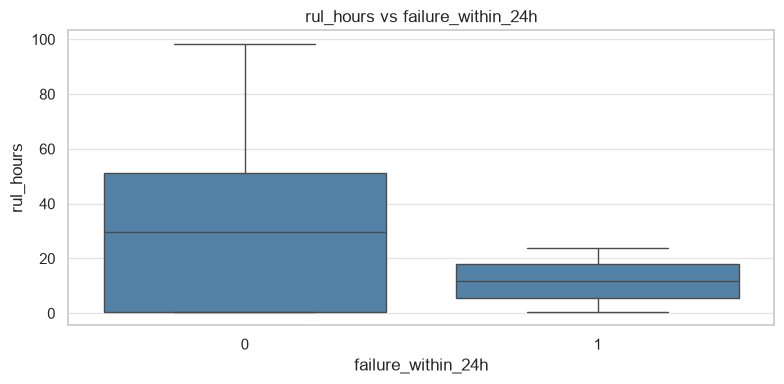

In [52]:
stats = df.groupby("failure_within_24h")["rul_hours"].agg(["median", "mean", "count"])
quantiles = (
    df.groupby("failure_within_24h")["rul_hours"]
      .quantile([0.25, 0.5, 0.75])
      .unstack()
      .round(2)
)
print("median / mean / count:")
print(stats.round(2))
print("\nquantiles (25%, 50%, 75%):")
print(quantiles)

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="failure_within_24h", y="rul_hours", ax=ax, color="steelblue")
ax.set_title("rul_hours vs failure_within_24h")
plt.tight_layout()
plt.show()

**Что видим:**

- Медиана RUL: 11.7 при `failure=1` против 29.8 при `failure=0`.
- При `failure=1` межквартильный размах (5.7..17.8) целиком ниже 24 — согласовано с определением.
- При `failure=0` 25-й перцентиль = 0.5 — то есть **много строк с RUL ≤ 24 помечены как «нет отказа»**. Это пересечение и есть та самая несогласованность, которую мы посчитали в 3.3.

**Вывод:** `rul_hours` — сильный сигнал, но таргет `failure_within_24h` — не идеальный порог по RUL. На этапе ML либо использовать `failure_within_24h` как отдельную цель, либо переопределить таргет из `rul_hours` (например, `rul_hours <= 24`) — но не оба одновременно как признаки.

### 5.3. Стоимость ремонта по типу отказа

In [53]:
df.groupby("failure_type", observed=True)["estimated_repair_cost"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
failure_type,,,,,,,,
bearing,1117.0,3734.0,728.0,2500.0,3078.0,3729.0,4362.0,4997.0
electrical,655.0,4043.0,1163.0,2002.0,3042.0,4071.0,5060.0,5992.0
hydraulic,728.0,2726.0,737.0,1502.0,2064.0,2690.0,3379.0,3998.0
motor_overheat,1060.0,5504.0,1458.0,3007.0,4229.0,5540.0,6764.0,7995.0
none,20482.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Что видим:**

- Самый дорогой тип — `motor_overheat` (медиана ~5540).
- Самый дешёвый — `hydraulic` (~2690).
- `bearing` и `electrical` — середина (~3730 и ~4070).
- `none` даёт стоимость 0 — согласовано с типом отказа.

Для бизнес-приложения это означает прямую денежную ценность `failure_type`, но в EDA мы не оптимизируем бизнес-метрику — только проверяем согласованность.

## 6. Multivariate — корреляции

### 6.1. Матрица Spearman

In [54]:
corr_cols = num_cols + ["failure_within_24h"]
corr = df[corr_cols].astype("float64").corr(method="spearman")
corr.round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h
vibration_rms,1.00,0.82,0.92,0.87,0.81,0.02,-0.00,0.01,0.18
temperature_motor,0.82,1.00,0.84,0.76,0.74,0.01,-0.00,-0.01,0.34
current_phase_avg,0.92,0.84,1.00,0.92,0.82,0.00,-0.00,0.02,0.15
pressure_level,0.87,0.76,0.92,1.00,0.75,-0.00,-0.01,0.04,0.01
rpm,0.81,0.74,0.82,0.75,1.00,-0.05,-0.01,0.04,-0.05
hours_since_maintenance,0.02,0.01,0.00,-0.00,-0.05,1.00,0.01,-0.43,0.08
ambient_temp,-0.00,-0.00,-0.00,-0.01,-0.01,0.01,1.00,-0.00,0.00
rul_hours,0.01,-0.01,0.02,0.04,0.04,-0.43,-0.00,1.00,-0.16
failure_within_24h,0.18,0.34,0.15,0.01,-0.05,0.08,0.00,-0.16,1.00


Используем **Spearman**, а не Pearson, потому что:
- распределения сенсоров бимодальные (из-за `operating_mode`);
- связи могут быть монотонными, но нелинейными;
- выбросы смещают Pearson, а Spearman работает с рангами и устойчив к ним.

### 6.2. Heatmap

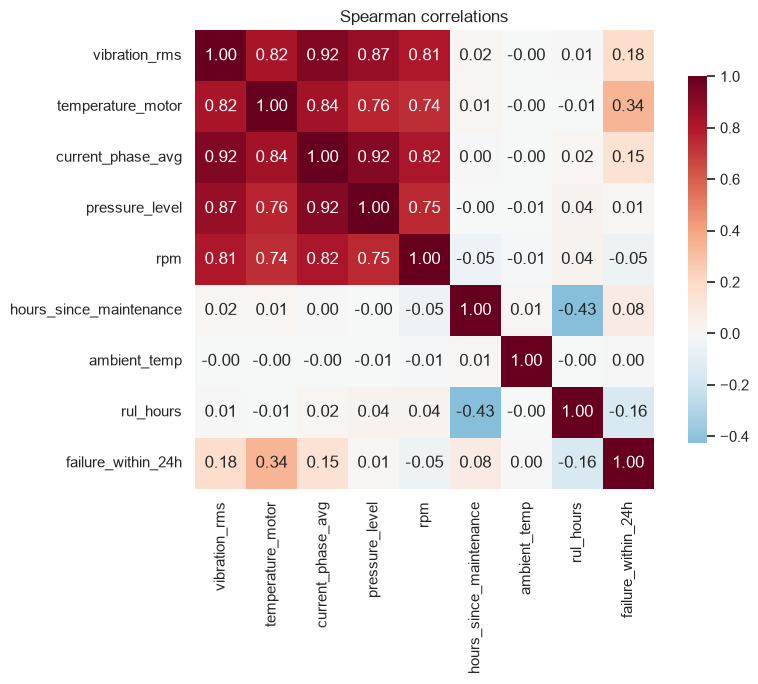

In [55]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Spearman correlations")
plt.tight_layout()
plt.show()

**Что видим:**

- Сенсоры **сильно коррелируют между собой** (0.74–0.92). Причина — общий латентный фактор «нагрузка на станок»: в `peak` все сенсоры одновременно растут. Типично для IoT.
- `hours_since_maintenance` и `rul_hours` связаны заметно отрицательно (ρ ≈ −0.43): чем дольше без ТО, тем меньше остаточный ресурс — физически логично.
- **Важно:** `rul_hours` ↔ `failure_within_24h` даёт всего ρ ≈ −0.16. Но по определению `failure=1` ⇔ `rul≤24`, а это должно давать заметно более сильную (пусть и не идеальную, из-за порога) корреляцию. Слабое значение — **прямое следствие несогласованности таргета**, найденной в 3.3: часть строк с малым RUL помечена как «нет отказа».
- `ambient_temp` не связан ни с чем — внешний фактор.
- Слабые корреляции таргета с сенсорами (`temperature_motor` 0.34 — сильнейшая) → нужны нелинейные модели и фиче-инжиниринг.

**Вывод для ML:** мультиколлинеарность сенсоров ломает стабильность линейных моделей; деревья и бустинги справятся. Таргет требует явной проверки/пересборки (см. 3.3).

## 7. Временная динамика

### 7.1. Наблюдения по часам суток

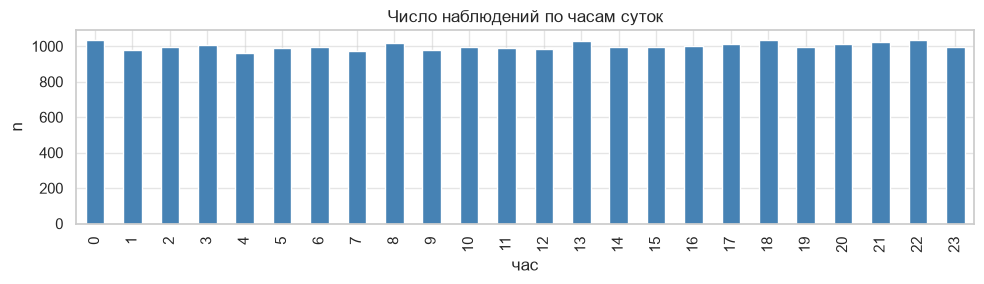

In [56]:
by_hour = df.groupby(df["timestamp"].dt.hour).size()
by_hour.plot(kind="bar", figsize=(10, 3), color="steelblue")
plt.title("Число наблюдений по часам суток")
plt.xlabel("час")
plt.ylabel("n")
plt.tight_layout()
plt.show()

**Что видим:** распределение по часам близко к равномерному — станки работают круглосуточно. Суточная сезонность слабая; для ML полезно добавить `hour_of_day`, но ожидать большого прироста не стоит.

### 7.2. Один станок: 24 часа до отказа

Берём **первый** переход `failure_within_24h: 0 → 1` у станка (фактический момент отказа) и строим окно 24 ч до него. Раньше брали последний — это склеивало разные эпизоды, если их несколько.

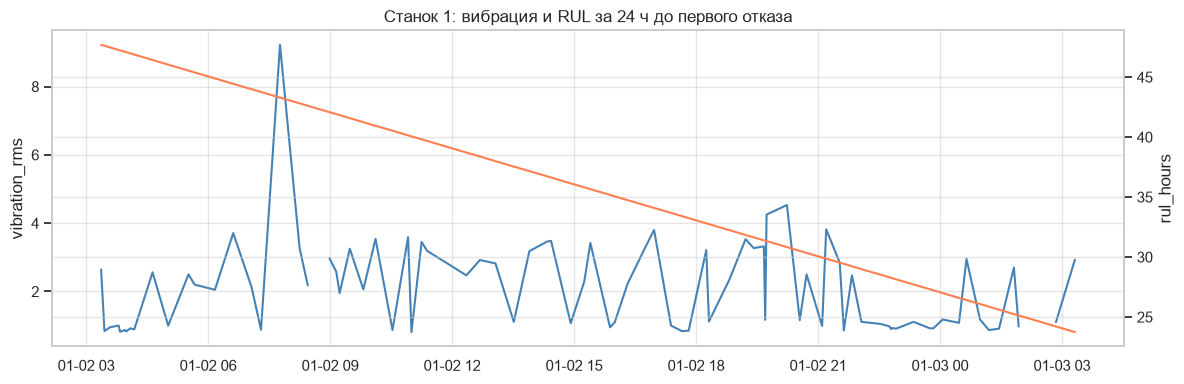

Окно: 2024-01-02 03:19:00 -> 2024-01-03 03:19:00
Строк в окне: 88


In [57]:
candidates = df.loc[df["failure_within_24h"] == 1, "machine_id"].unique()
if len(candidates) == 0:
    print("В датасете нет строк с failure_within_24h = 1 — график не строится")
else:
    sample_machine = int(candidates[0])
    sub_full = df[df["machine_id"] == sample_machine].sort_values("timestamp").copy()
    # Первый переход 0 -> 1 (фактический момент отказа, а не последний эпизод)
    sub_full["prev_flag"] = sub_full["failure_within_24h"].shift(1).fillna(0)
    transitions = sub_full[(sub_full["failure_within_24h"] == 1) &
                           (sub_full["prev_flag"] == 0)]
    if transitions.empty:
        print(f"У станка {sample_machine} не найдено перехода 0->1; берём первый момент с failure=1")
        first_fail_ts = sub_full.loc[sub_full["failure_within_24h"] == 1, "timestamp"].min()
    else:
        first_fail_ts = transitions["timestamp"].iloc[0]
    window_start = first_fail_ts - pd.Timedelta(hours=24)
    sub = sub_full[(sub_full["timestamp"] >= window_start) &
                   (sub_full["timestamp"] <= first_fail_ts)]

    fig, ax1 = plt.subplots(figsize=(12, 4))
    ax1.plot(sub["timestamp"], sub["vibration_rms"], color="steelblue", label="vibration_rms")
    ax1.set_ylabel("vibration_rms")

    ax2 = ax1.twinx()
    ax2.plot(sub["timestamp"], sub["rul_hours"], color="coral", label="rul_hours")
    ax2.set_ylabel("rul_hours")
    plt.title(f"Станок {sample_machine}: вибрация и RUL за 24 ч до первого отказа")
    plt.tight_layout()
    plt.show()

    print(f"Окно: {window_start} -> {first_fail_ts}")
    print(f"Строк в окне: {len(sub)}")

### 8. Качество данных — резюме

- **Структура:** полный, уникальный ключ `(timestamp, machine_id)`, все станки представлены равномерно (~1141–1298 строк на станок).
- **Типы:** приведены корректно: `datetime64`, `category`, `Int64`, `int8`, `float64`. Память ~2.16 МБ.
- **Пропуски:** только в сенсорах, 2.2–4.2%; стратегию заполнения — на этапе ML (forward-fill / медиана по `machine_id`).
- **Дубликаты:** отсутствуют (ни полных, ни по ключу `(timestamp, machine_id)`).
- **Доменные проверки:** диапазоны реалистичны; проверки `vibration_rms ≥ 0`, `temperature_motor ∈ [20, 120]`, `rpm ≥ 0`, `rul_hours ≥ 0`, `failure_within_24h ∈ {0, 1}`, «стоимость = 0 при `failure_type = none`» проходят.
- **Согласованность таргета:** проверено тождество `failure=1 ⇔ rul≤24` — **8800 расхождений (36.6%)**, все в сторону `rul≤24 & failure=0`. Это **главная проблема данных**: таргет «запаздывает» относительно RUL.
- **Монотонность RUL:** найдено **17 скачков** роста `rul_hours` (>5 ч) при растущем `hours_since_maintenance`, т.е. без сброса часов ТО (например, у станка 1 около `2024-01-02 03:04`). Артефакт синтетики.
- **Нижняя отсечка RUL:** у ~25% строк `rul_hours` ровно 0.5 — искусственная нижняя граница, а не «сломан сейчас».
- **Выбросы:** 1–3% по каждому признаку; чаще всего это реальные экстремумы (`peak`-режим, предотказное состояние), а не ошибки. Удаление не рекомендуется.
- **Дисбаланс классов:** `failure_within_24h` ~14.8% положительных — умеренный, решается `class_weight` или `scale_pos_weight`.
- **Мультиколлинеарность:** высокая между сенсорами (ρ Спирмена 0.74–0.92) — учитывать при выборе модели.
- **Связи с таргетом (Spearman):** слабые — сильнейшая `temperature_motor` (0.34). Слабая `rul ↔ failure` (−0.16) противоречит определению таргета → подтверждает несогласованность из 3.3.

## 9. Продвинутая визуализация (Plotly)

Этот раздел **добавлен к исходному EDA**. Разделы 1–8 и их код не изменены. Здесь строим дополнительные интерактивные графики на Plotly Express, используя уже подготовленный `df` и рассчитанные ранее признаки.

### 9.1. Распределения числовых признаков

Интерактивные гистограммы для тех же числовых признаков, которые исследовались в разделе 4.1.

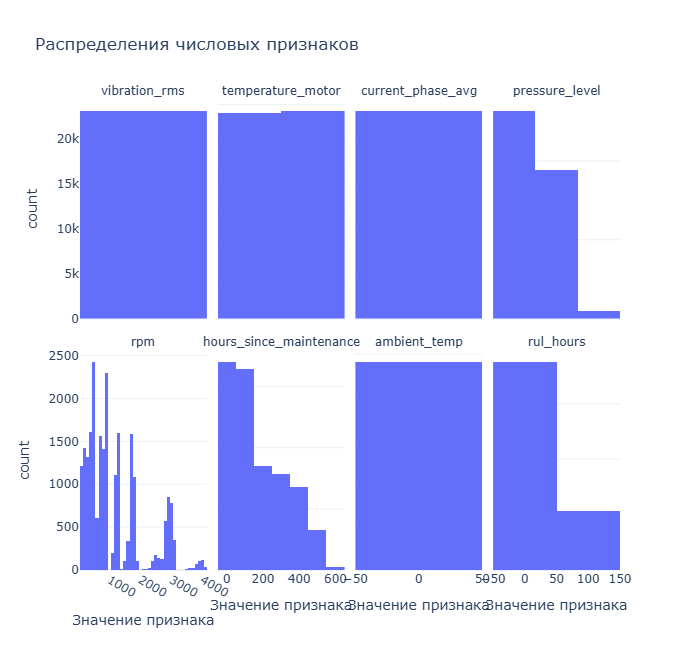

In [58]:
import plotly.express as px
import plotly.io as pio

pio.templates.default = "plotly_white"
# Для статического вывода PNG требуется установленный Kaleido и совместимый Chrome.
# Если PNG-рендерер недоступен в вашей среде, используйте: pio.renderers.default = "plotly_mimetype"
pio.renderers.default = "png"

hist_long = df[num_cols].melt(var_name="Признак", value_name="Значение").dropna()
fig = px.histogram(
    hist_long, x="Значение", facet_col="Признак", facet_col_wrap=4,
    nbins=60, title="Распределения числовых признаков",
    labels={"Значение": "Значение признака"}
)
fig.update_xaxes(matches=None)
fig.update_yaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(showlegend=False, height=650)
fig.show()

### 9.2. Сравнение типов станков и целевой переменной

Дополнительные Plotly boxplot-графики показывают распределения вибрации и RUL по типам оборудования, а также различия RUL для двух классов `failure_within_24h`.

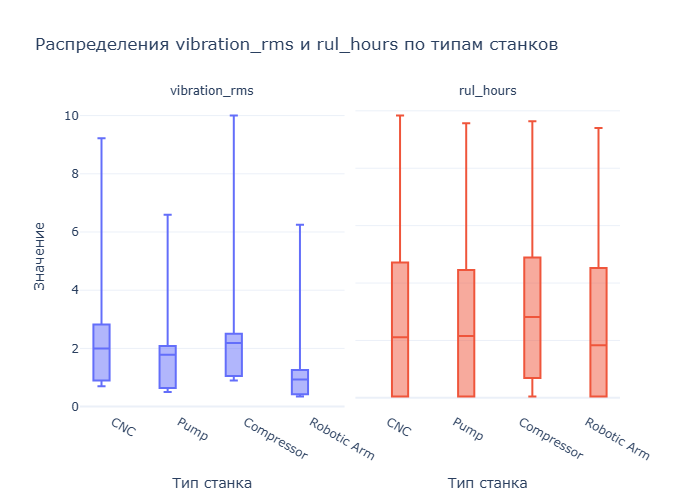

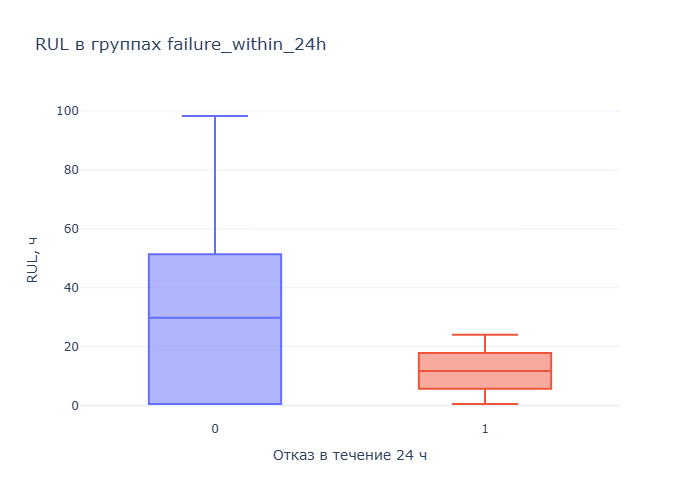

In [59]:
box_long = df[["machine_type", "vibration_rms", "rul_hours"]].melt(
    id_vars="machine_type", var_name="Показатель", value_name="Значение"
).dropna()
fig = px.box(
    box_long, x="machine_type", y="Значение", color="Показатель",
    facet_col="Показатель", points=False,
    title="Распределения vibration_rms и rul_hours по типам станков",
    labels={"machine_type":"Тип станка", "Значение":"Значение"}
)
fig.update_yaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(showlegend=False)
fig.show()

fig = px.box(
    df, x="failure_within_24h", y="rul_hours", color="failure_within_24h",
    points=False, title="RUL в группах failure_within_24h",
    labels={"failure_within_24h":"Отказ в течение 24 ч", "rul_hours":"RUL, ч"}
)
fig.update_layout(showlegend=False)
fig.show()

### 9.3. Корреляции и временная динамика

Интерактивная тепловая карта Spearman-корреляций и графики временного распределения наблюдений. Используется матрица `corr`, рассчитанная в разделе 6.

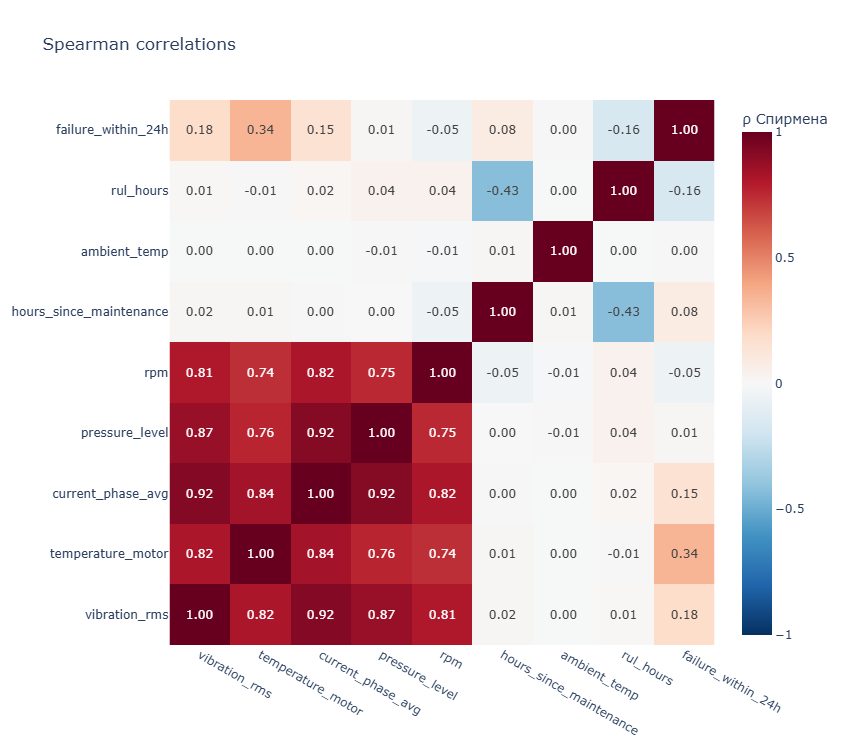

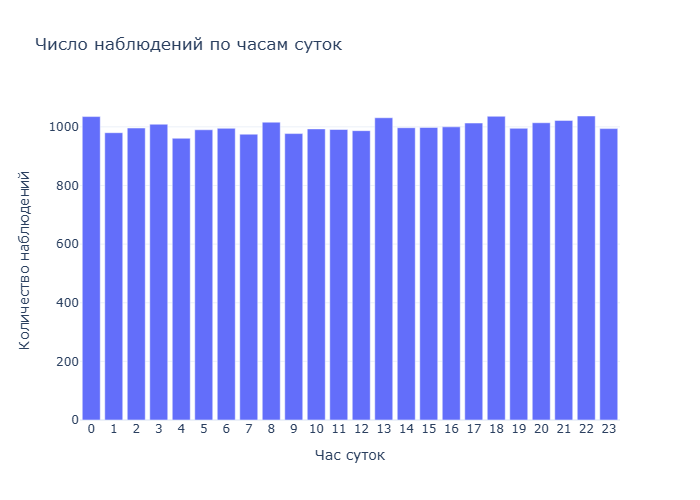

In [60]:
fig = px.imshow(
    corr, text_auto=".2f", color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1, origin="lower", aspect="equal",
    title="Spearman correlations"
)
fig.update_layout(width=850, height=750, coloraxis_colorbar=dict(title="ρ Спирмена"))
fig.show()

hourly_plot = by_hour.rename("n").rename_axis("hour").reset_index()
fig = px.bar(
    hourly_plot, x="hour", y="n",
    title="Число наблюдений по часам суток",
    labels={"hour":"Час суток", "n":"Количество наблюдений"}
)
fig.update_xaxes(dtick=1)
fig.show()

### 9.4. Структура стоимости ремонтов

Treemap показывает вклад типов отказов и типов оборудования в суммарную оценочную стоимость ремонта. Стоимость в исходном датасете может повторяться в нескольких телеметрических строках, поэтому график отражает сумму по строкам, а не число уникальных ремонтов.

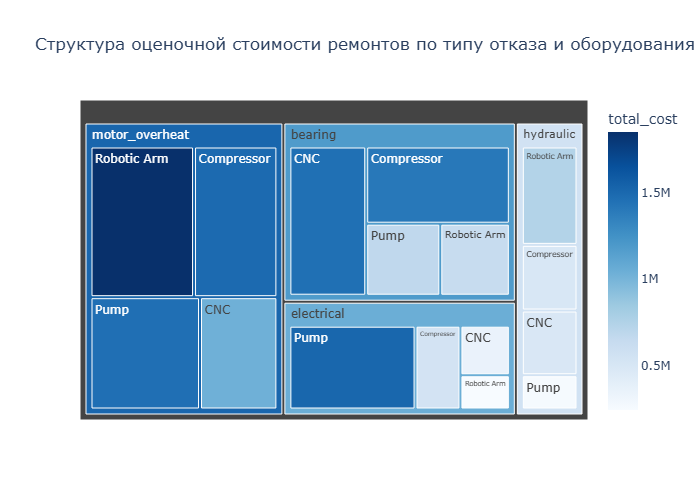

In [61]:
repair_summary = (
    df.groupby(["failure_type", "machine_type"], observed=True, as_index=False)
      .agg(total_cost=("estimated_repair_cost", "sum"), records=("estimated_repair_cost", "size"))
)
repair_summary = repair_summary[repair_summary["total_cost"] > 0]
fig = px.treemap(
    repair_summary, path=["failure_type", "machine_type"], values="total_cost",
    color="total_cost", color_continuous_scale="Blues",
    hover_data={"records":True, "total_cost":":,.0f"},
    title="Структура оценочной стоимости ремонтов по типу отказа и оборудования"
)
fig.show()